# Payoff based NE estimaton algorithms comparisson

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from payoffnash.gaussian_estimator import GaussianEstimator
from payoffnash.ne_seeking import NE_Seeking

# Duopoly game comparison

# Parameters
Sd = 100.0
p = 0.2
m1 = 30.0
m2 = 30.0

# Payoff functions
def J1(u1, u2):
        s1 = Sd - (u1 - u2) / p
        profit = s1 * (u1 - m1)
        return profit 
    
def J2(u1, u2):
        s2 = (u1 - u2) / p
        profit = s2 * (u2 - m2)
        return profit

NE_Seeking (1000000 iterations):
Final Estimates: [array([43.07426699]), array([36.61996797])]
Total Regret: 7335369.02



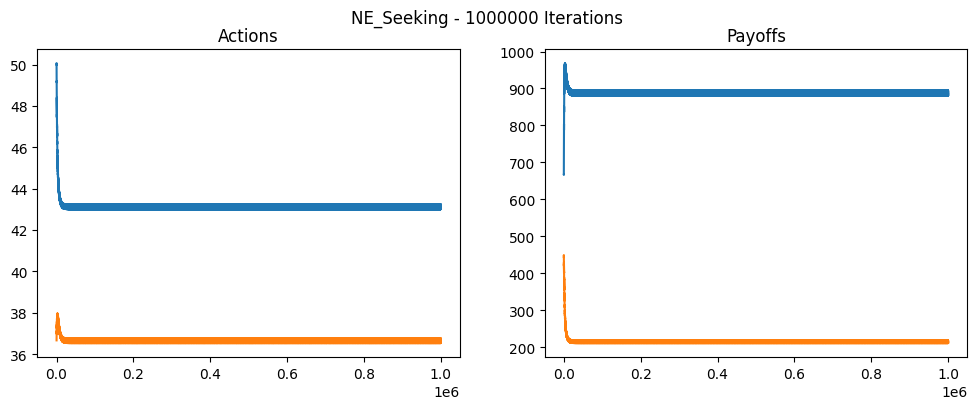

GaussianEstimator (1000000 iterations):
Final Estimates: [array([43.37543165]), array([36.68616141])]
Total Regret: 199821749.75



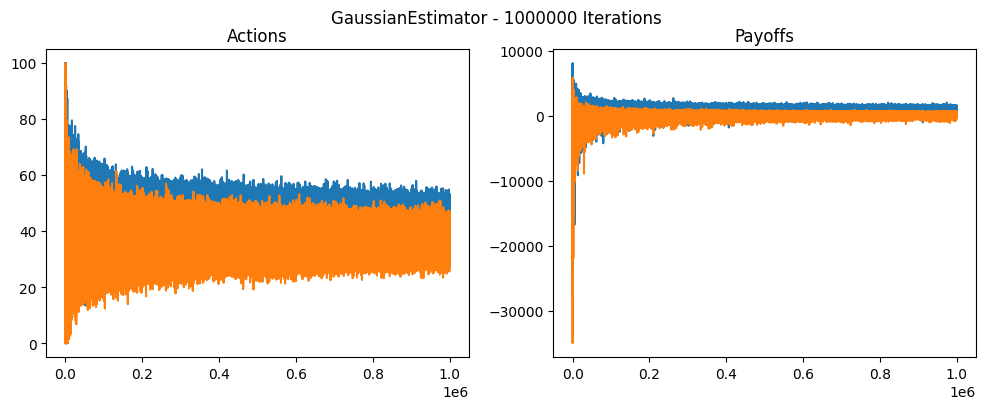

In [5]:
# Define theoretical NE and optimal payoffs
NE_1, NE_2 = 43.3333, 36.6667
J1_opt = 100 * (NE_1 - 30) - ((NE_1 - NE_2)/0.2) * (NE_1 - 30)
J2_opt = ((NE_1 - NE_2)/0.2) * (NE_2 - 30)
THEORETICAL_PAYOFFS = [J1_opt, J2_opt]

def run_simulation(N_iters):
    # Setup for NE_Seeking
    ne_sim = NE_Seeking(2, [[(0, 100)], [(0, 100)]], [J1, J2], 
                        [np.array([2.0]), np.array([5.0])], 
                        [np.array([0.075]), np.array([0.05])],
                        [np.array([26.75]), np.array([22.0])], [np.array([0.0]), np.array([0.0])])
    
    # Setup for GaussianEstimator
    gauss_sim = GaussianEstimator(2, [[(0, 100)], [(0, 100)]], [J1, J2], a=100, epsilon=0.001)
    
    init = [np.array([50.0]), np.array([36.6667])]
    
    # Run
    res_ne = ne_sim.estimate(init, num_steps=N_iters)
    res_gauss = gauss_sim.estimate(init, N_iters=N_iters)
    
    return res_ne, res_gauss

def plot_and_regret(results, title_prefix, N_iters):
    actions, payoffs = np.array(results[1]), np.array(results[2])
    
    # Regret calculation
    regret = np.sum(np.array(THEORETICAL_PAYOFFS) - payoffs, axis=1)
    print(f"{title_prefix} ({N_iters} iterations):")
    print(f"Final Estimates: {results[0]}")
    print(f"Total Regret: {np.sum(regret):.2f}\n")

    fig, ax = plt.subplots(1, 2, figsize=(12, 4))
    ax[0].plot(actions); ax[0].set_title("Actions")
    ax[1].plot(payoffs); ax[1].set_title("Payoffs")
    plt.suptitle(f"{title_prefix} - {N_iters} Iterations")
    plt.show()

# Execution for specified counts
for n in [1000000]:
    ne_res, g_res = run_simulation(n)
    plot_and_regret(ne_res, "NE_Seeking", n)
    plot_and_regret(g_res, "GaussianEstimator", n)